
 RUNNING ANALYSIS: Combined Families (CD3A, SP34) [Within-Family Z-Scored] (n = 197 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING ---
                                   Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW  p_value Sig
Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                 0.326763        0.326763 0.000003 ***
     Lower VH-VL Dipole (-ΔCharge Asym Z)                 0.296494        0.296494 0.000023 ***
                 Higher ESM-2 Fitness (Z)                 0.289697       -0.289697 0.000036 ***
        Further from pH 7.4 (Δ|pI-7.4| Z)                 0.255559       -0.255559 0.000290 ***
        Higher Net Charge (ΔNet Charge Z)                 0.234681       -0.234681 0.000902 ***
               Higher AbLang2 Fitness (Z)                 0.200133        0.200133 0.004807  **
                 Higher ESM-C Fitness (Z)                 0.153719       -0.153719 0.031033   *
           Higher Stability (Janus ΔΔG Z)                 0.140854       -0.140854 0.048352   *
  

/tmp/ipykernel_2637359/1955645917.py:260: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


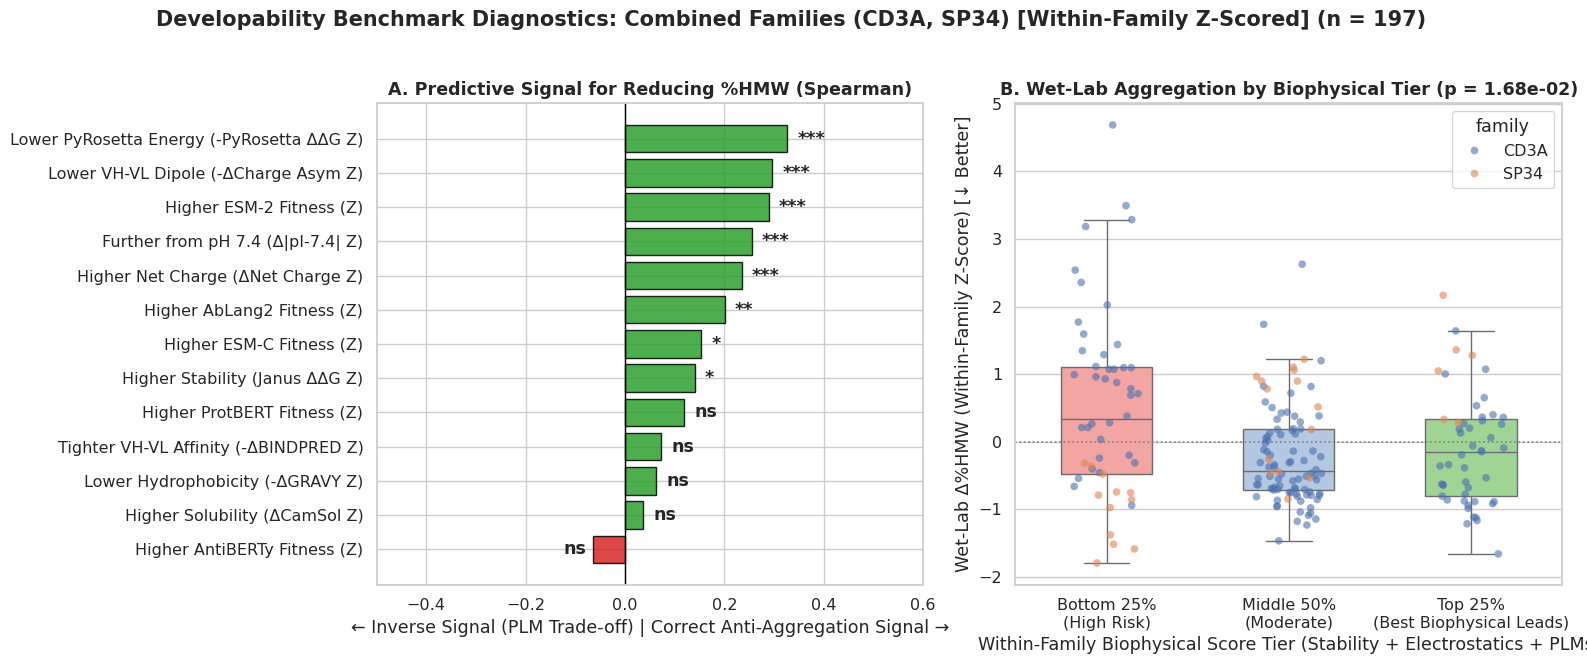

 -> Saved: hmw_benchmark_diagnostics_zscore_combined_CD3A_SP34.png


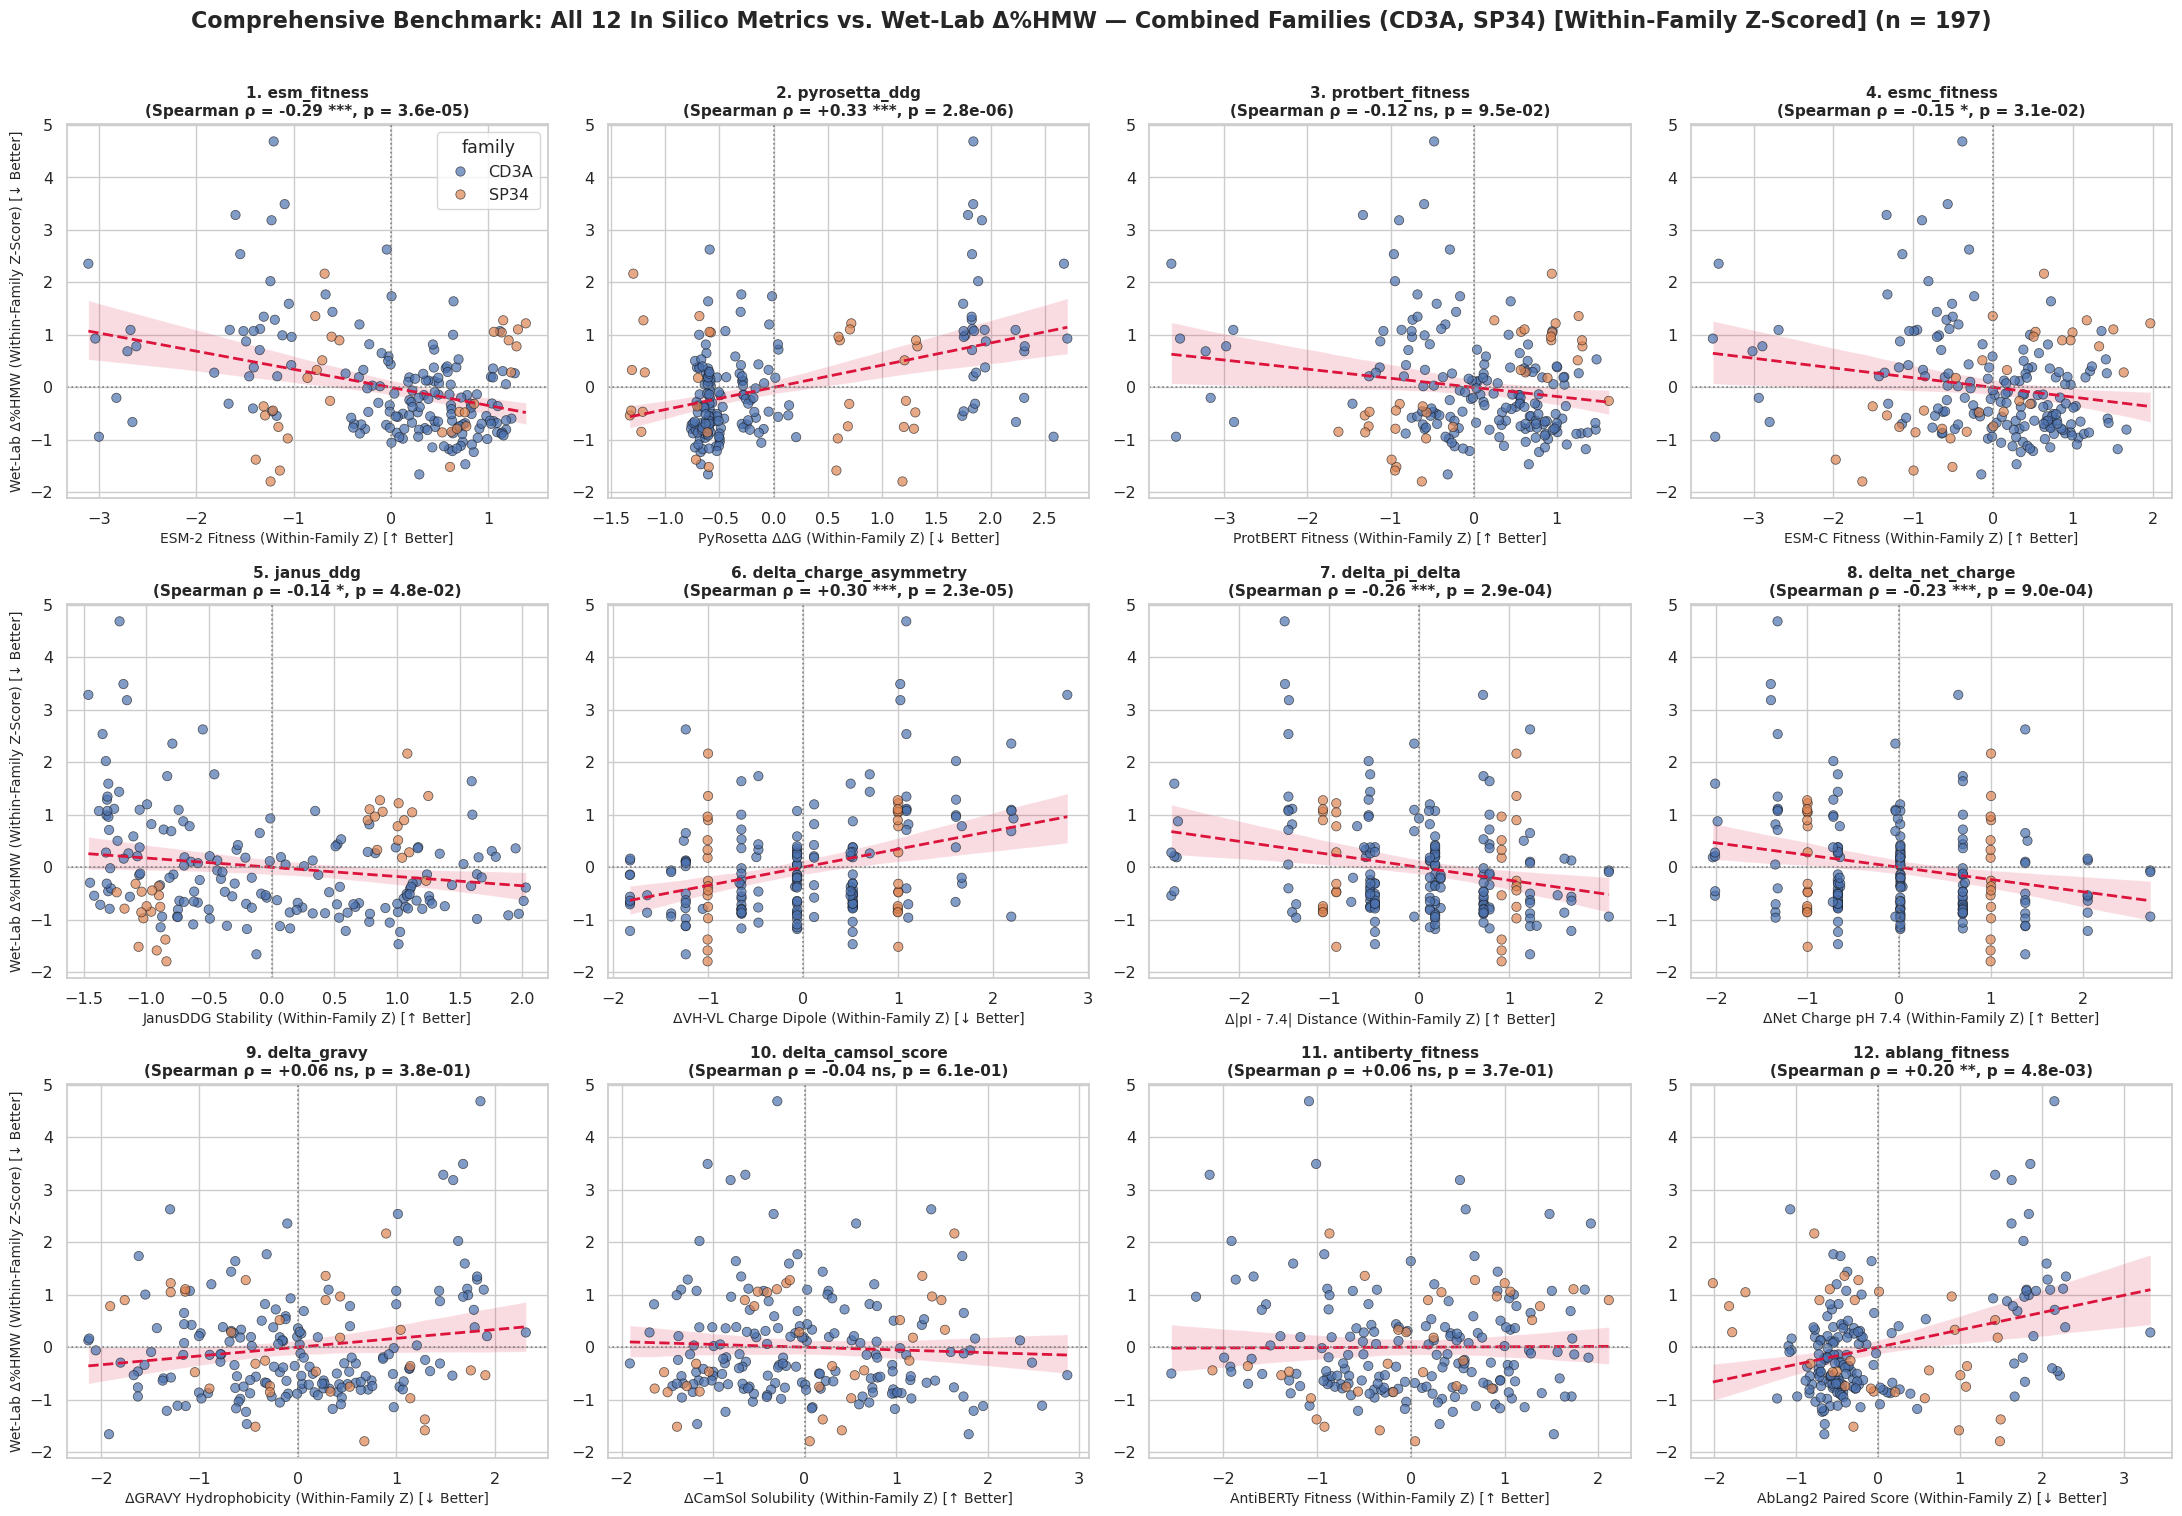

 -> Saved: all_metrics_scatter_grid_zscore_combined_CD3A_SP34.png


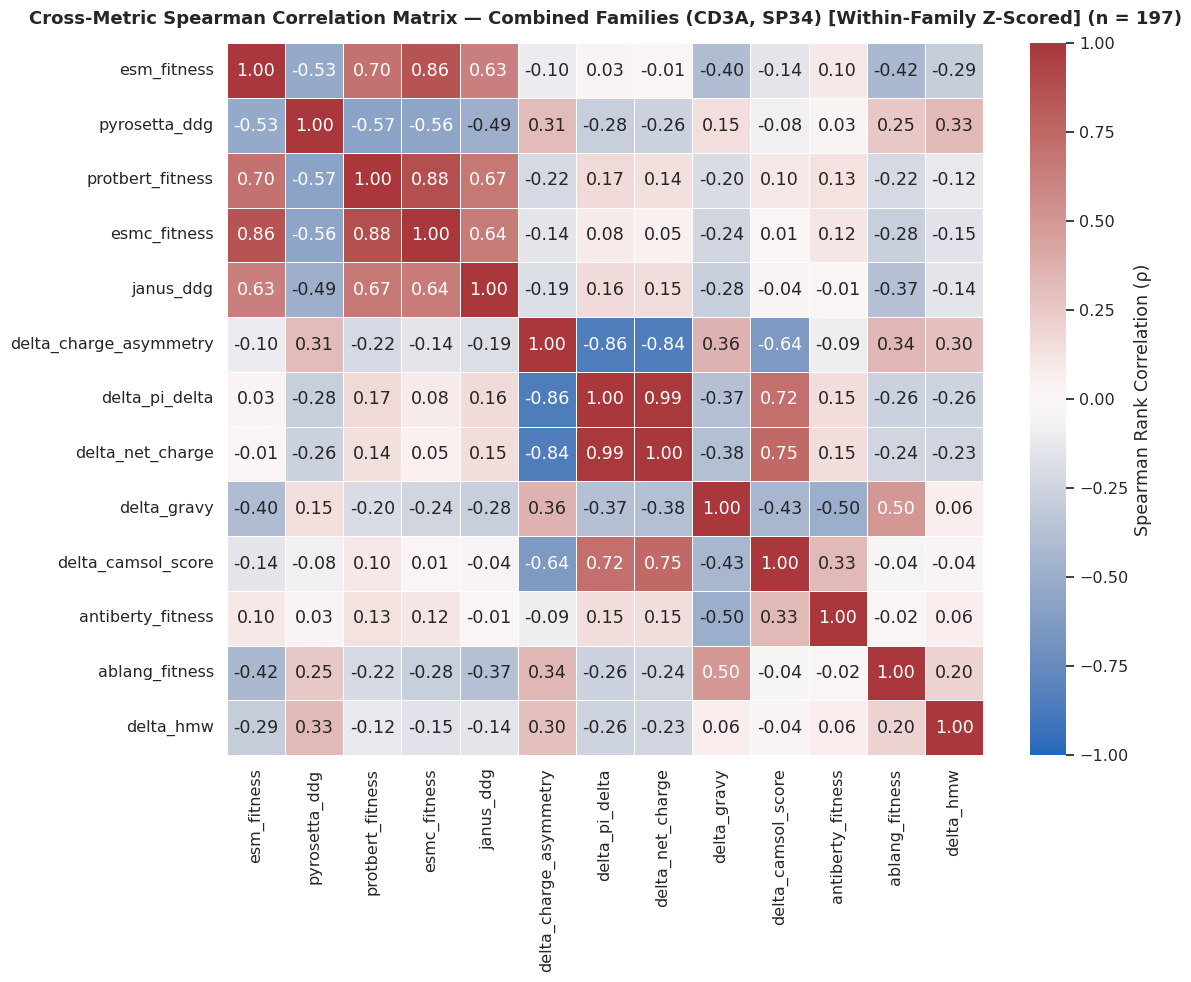

 -> Saved: metrics_cross_correlation_heatmap_zscore_combined_CD3A_SP34.png

 RUNNING ANALYSIS: Family: CD3A [Within-Family Z-Scored] (n = 165 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING ---
                                   Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
                 Higher ESM-2 Fitness (Z)                 0.444850       -0.444850 2.147267e-09 ***
Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                 0.413455        0.413455 3.398939e-08 ***
              Higher ProtBERT Fitness (Z)                 0.384728       -0.384728 3.358846e-07 ***
                 Higher ESM-C Fitness (Z)                 0.384221       -0.384221 3.490517e-07 ***
           Higher Stability (Janus ΔΔG Z)                 0.352960       -0.352960 3.320430e-06 ***
               Higher AbLang2 Fitness (Z)                 0.340932        0.340932 7.427588e-06 ***
     Lower VH-VL Dipole (-ΔCharge Asym Z)                 0.319477        0.319477 2.880660e-05 ***
        F

/tmp/ipykernel_2637359/1955645917.py:260: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


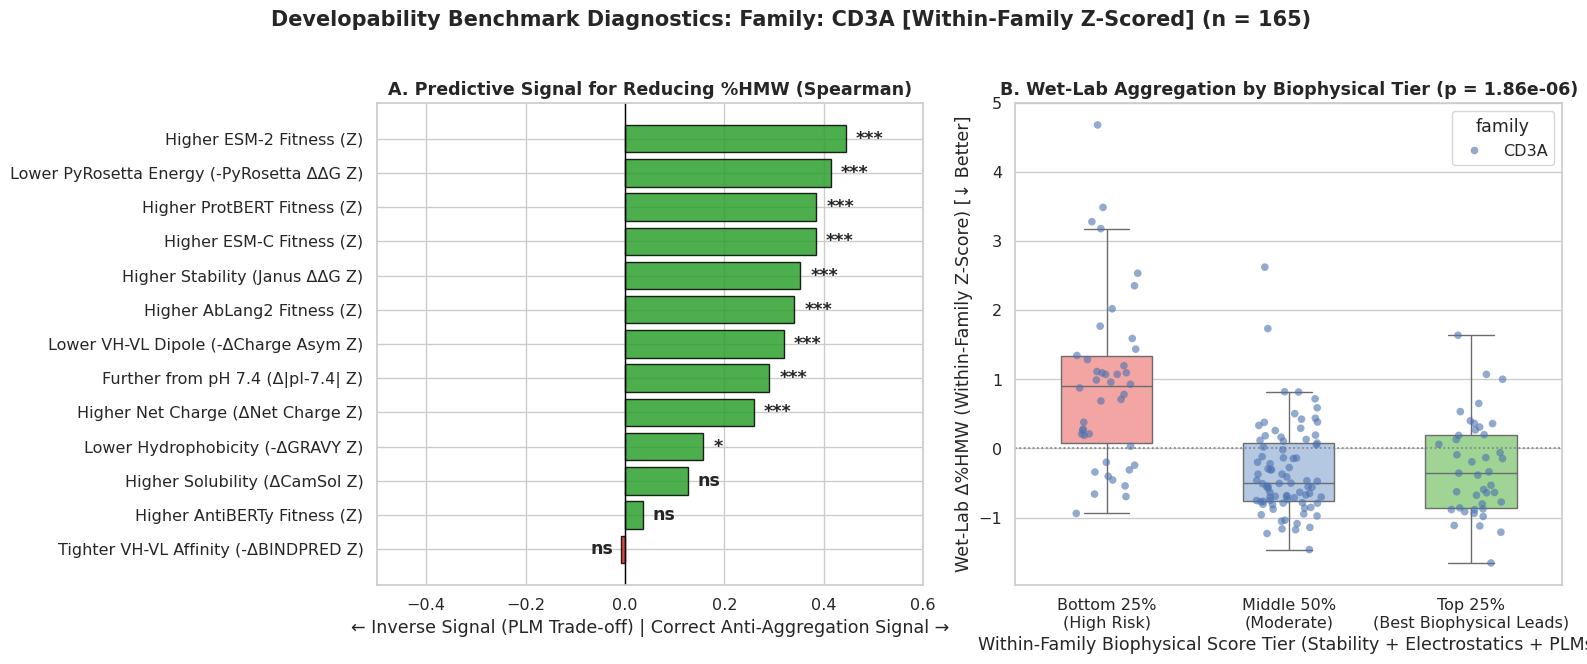

 -> Saved: hmw_benchmark_diagnostics_zscore_CD3A.png


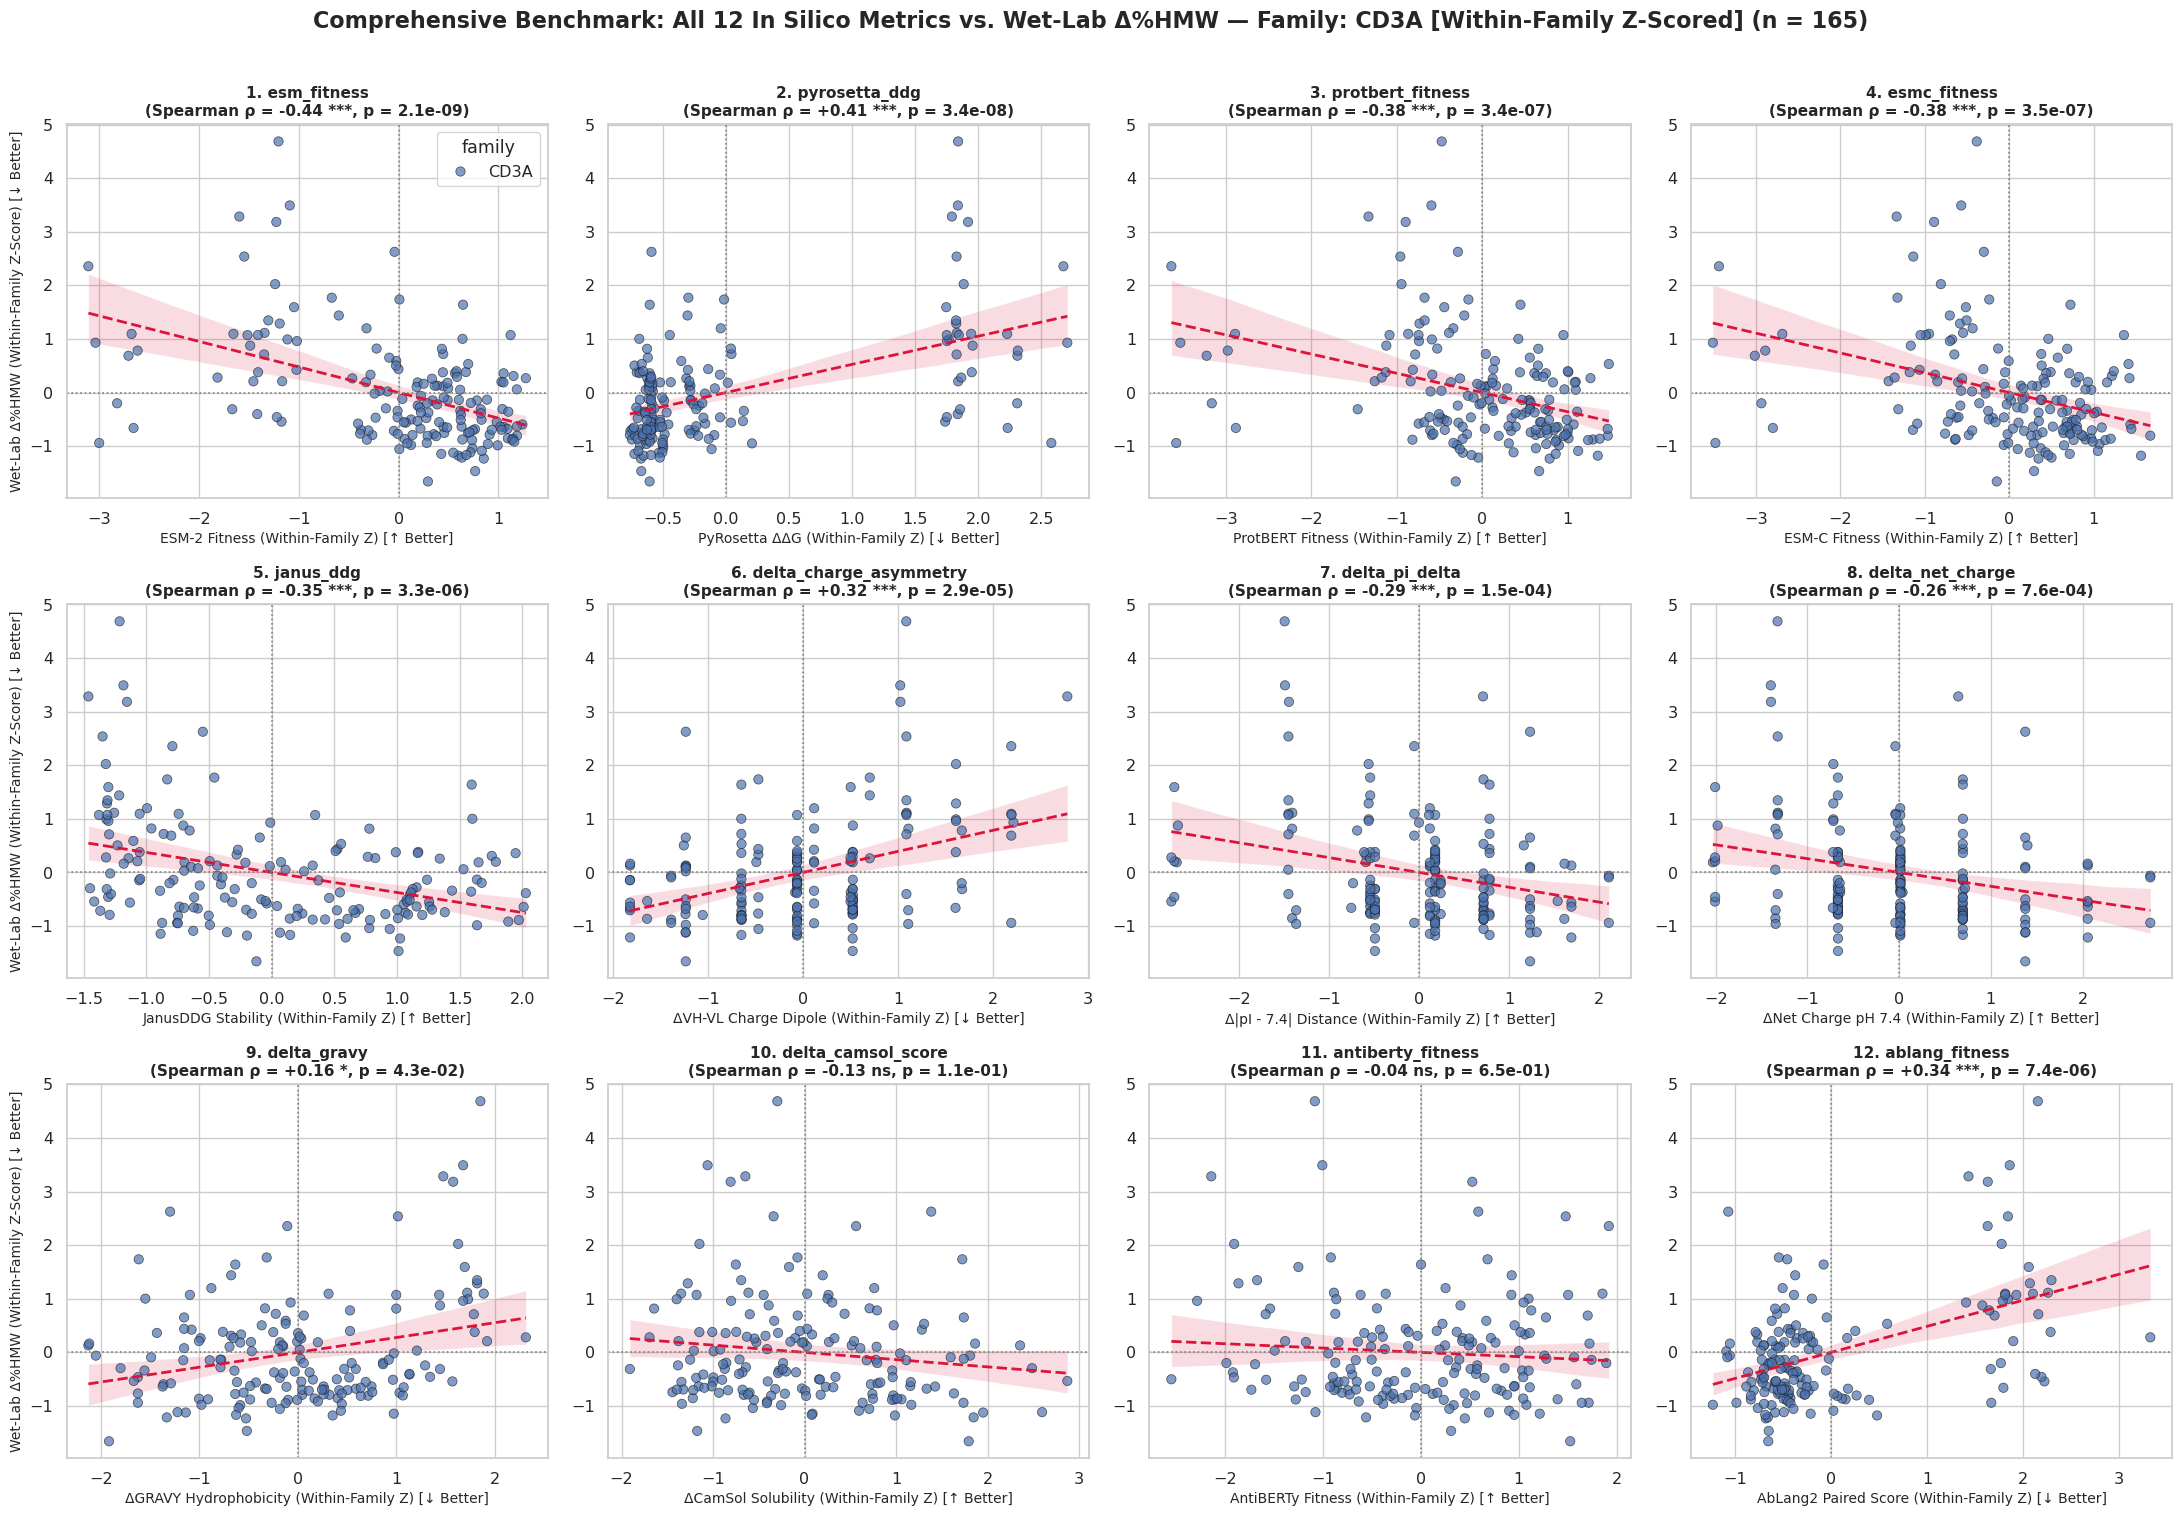

 -> Saved: all_metrics_scatter_grid_zscore_CD3A.png


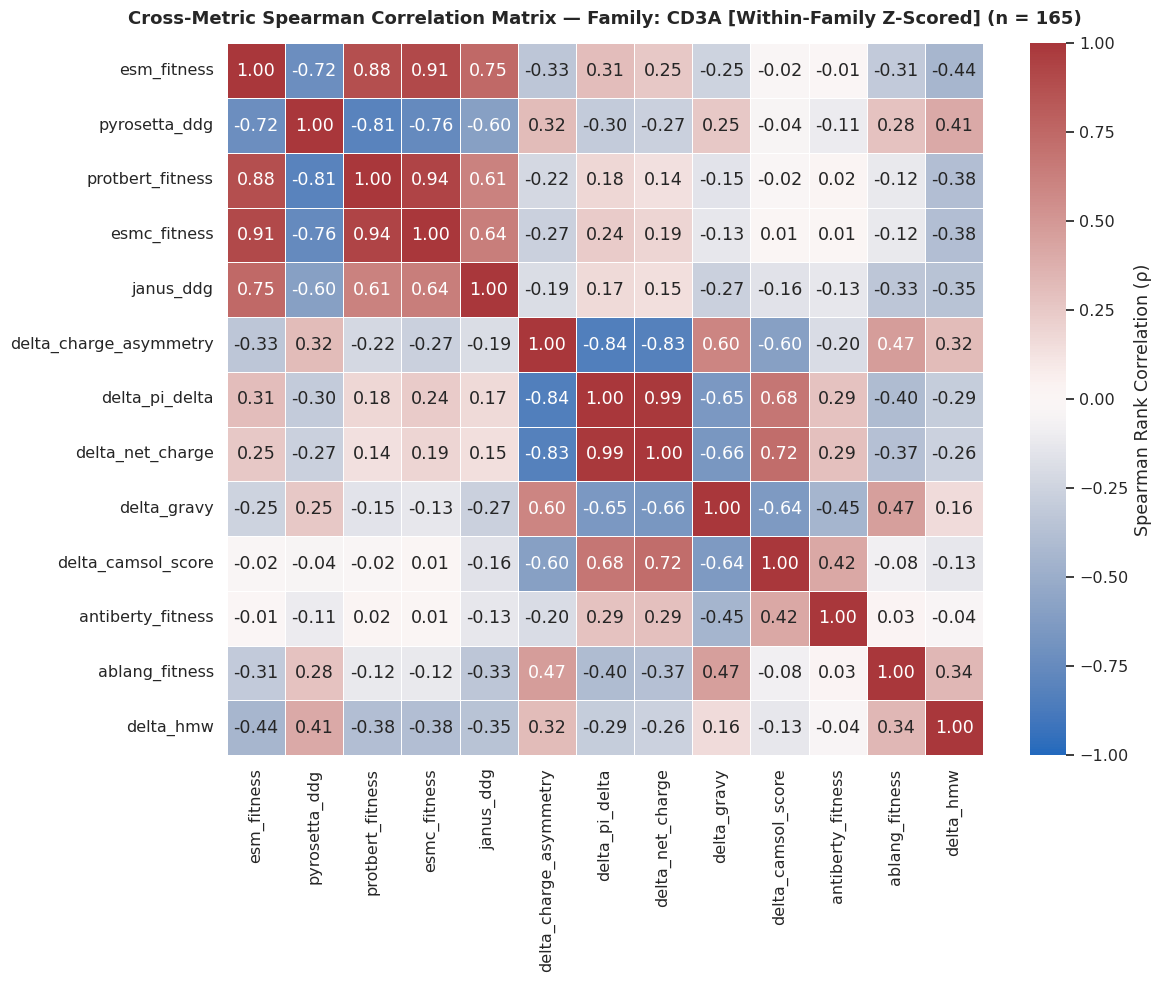

 -> Saved: metrics_cross_correlation_heatmap_zscore_CD3A.png

 RUNNING ANALYSIS: Family: SP34 [Within-Family Z-Scored] (n = 32 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING ---
                                   Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
    Tighter VH-VL Affinity (-ΔBINDPRED Z)                 0.416460        0.416460 1.774112e-02   *
     Lower VH-VL Dipole (-ΔCharge Asym Z)                 0.161973        0.161973 3.757955e-01  ns
        Further from pH 7.4 (Δ|pI-7.4| Z)                 0.025734       -0.025734 8.888145e-01  ns
        Higher Net Charge (ΔNet Charge Z)                 0.025734       -0.025734 8.888145e-01  ns
Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                -0.005682       -0.005682 9.753768e-01  ns
            Higher Solubility (ΔCamSol Z)                -0.331592        0.331592 6.374149e-02  ns
         Lower Hydrophobicity (-ΔGRAVY Z)                -0.427458       -0.427458 1.467663e-02   *
                 Higher 

/tmp/ipykernel_2637359/1955645917.py:260: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


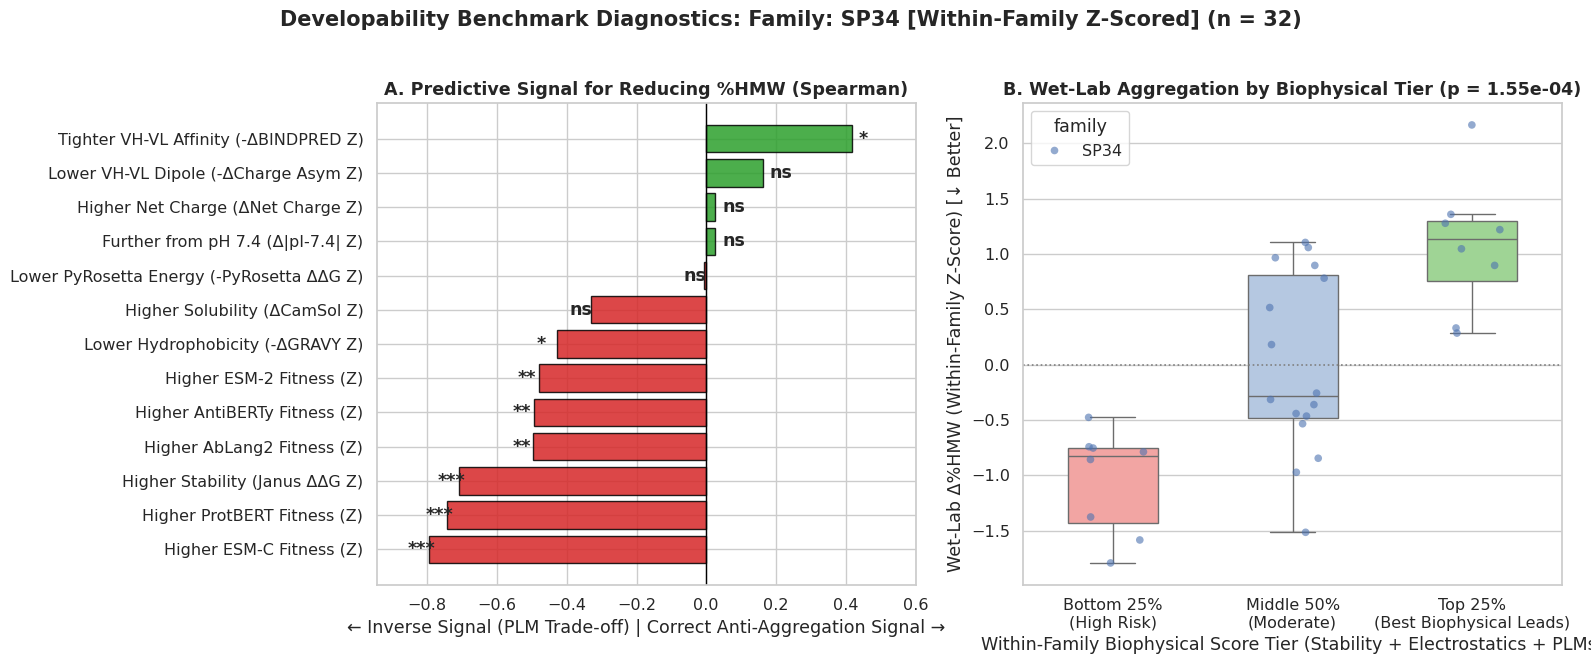

 -> Saved: hmw_benchmark_diagnostics_zscore_SP34.png


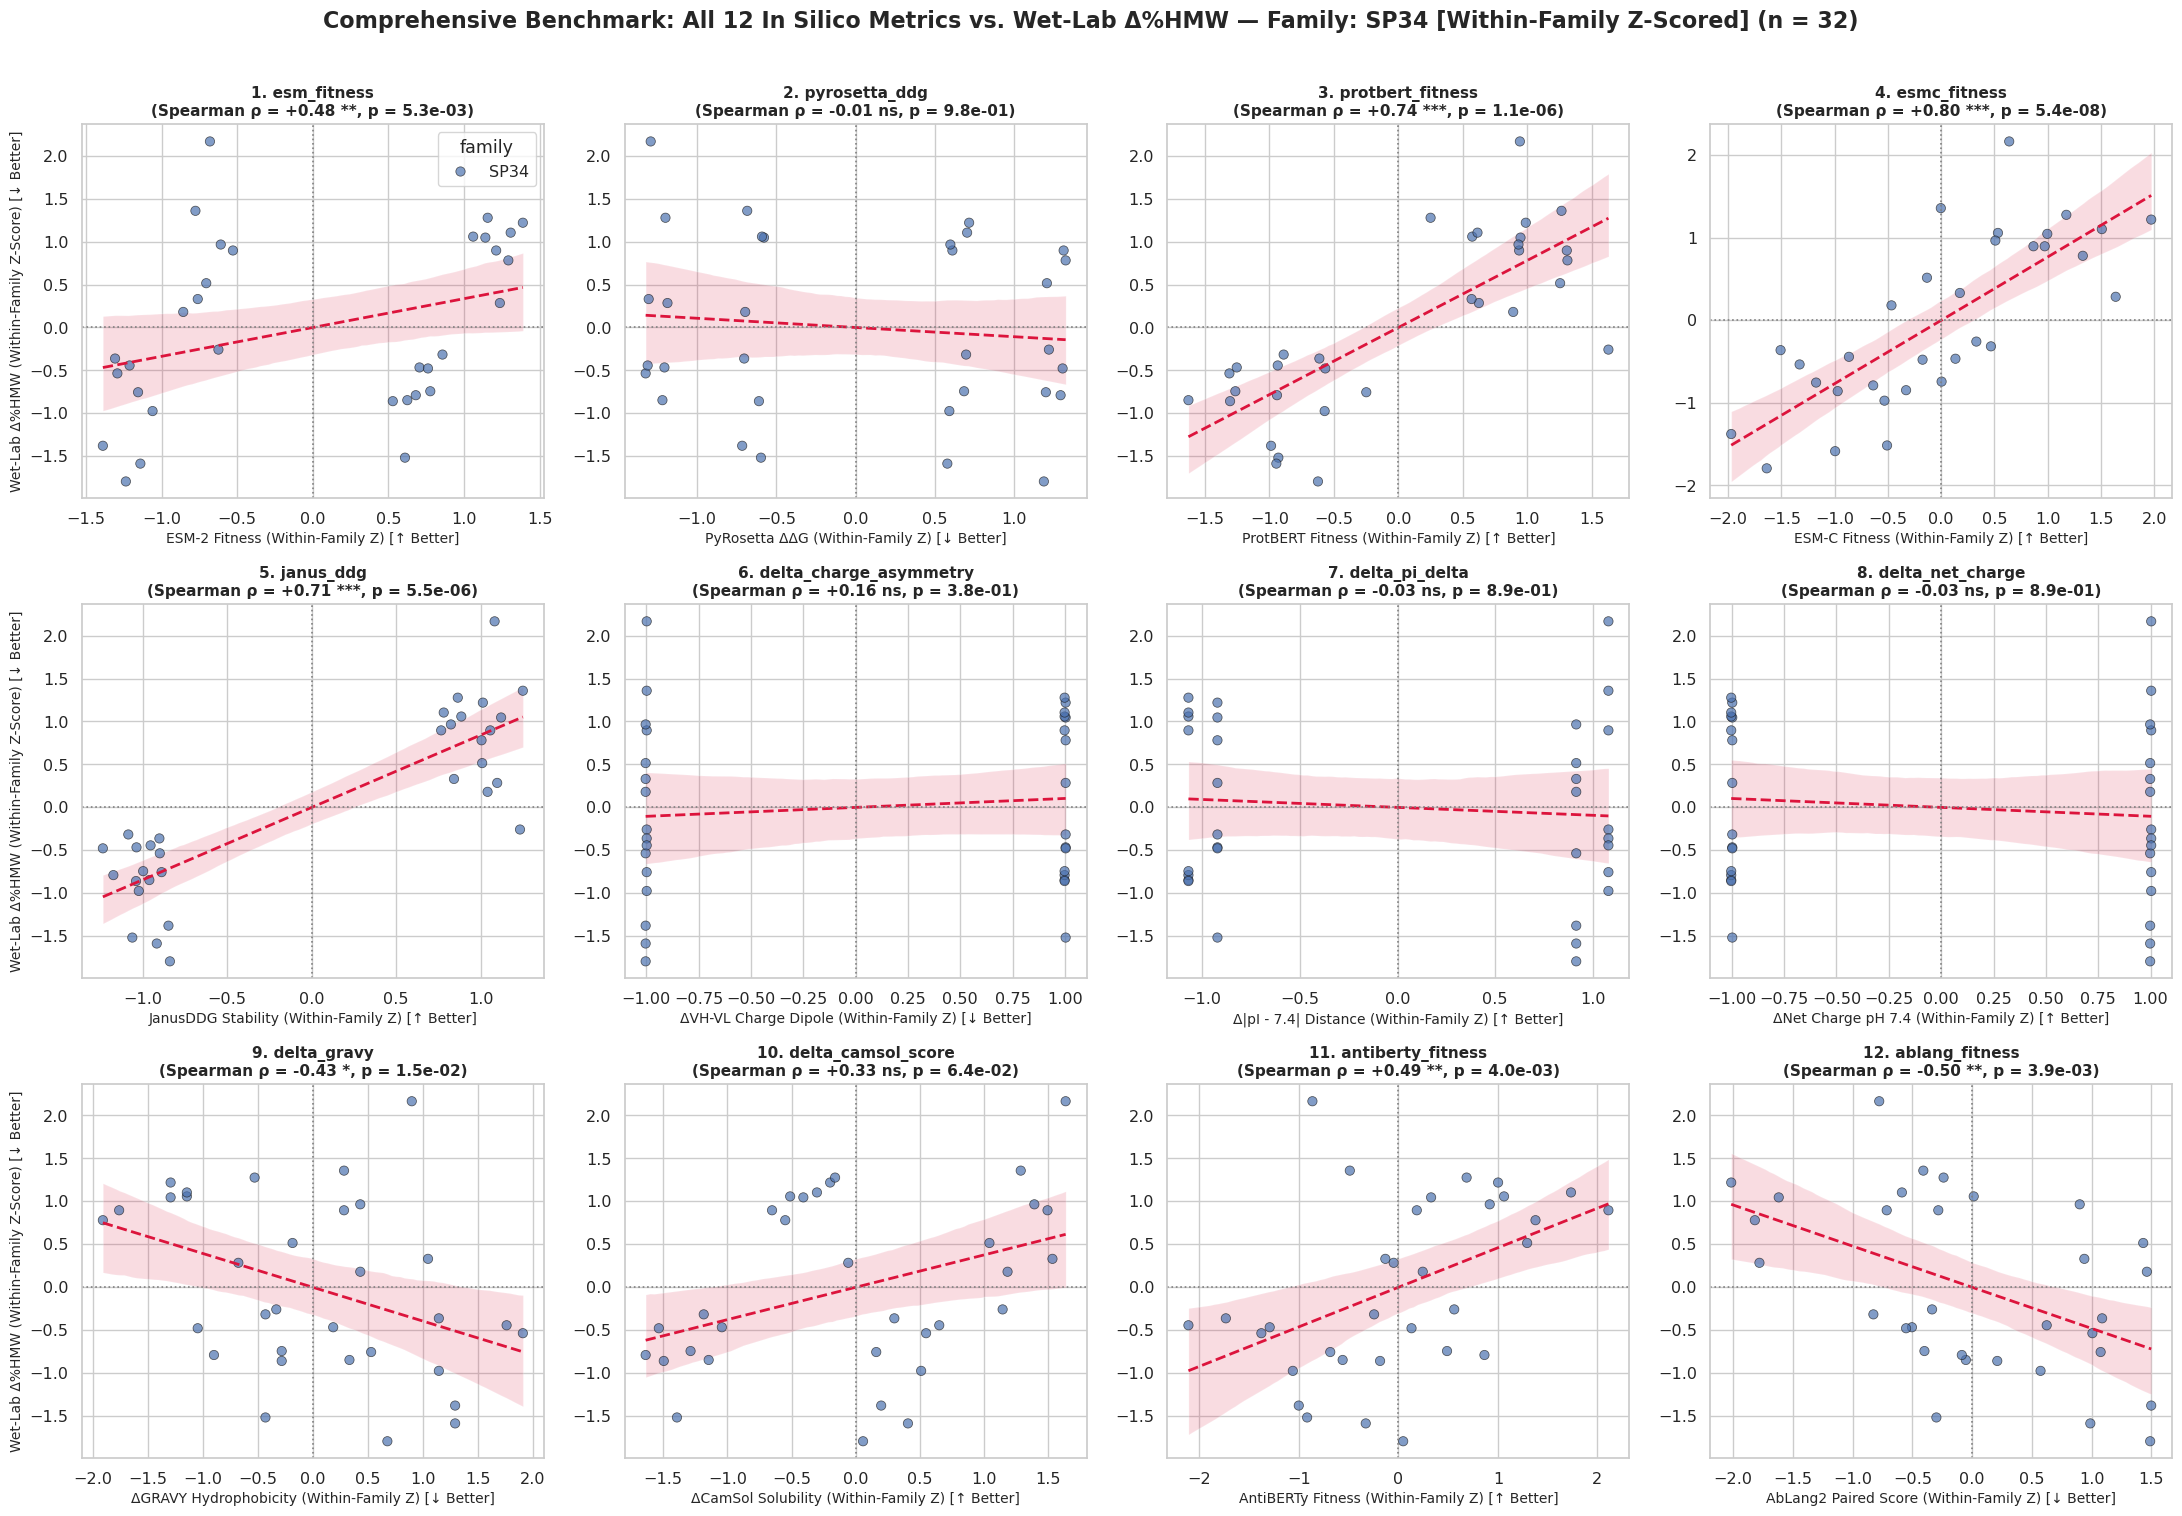

 -> Saved: all_metrics_scatter_grid_zscore_SP34.png


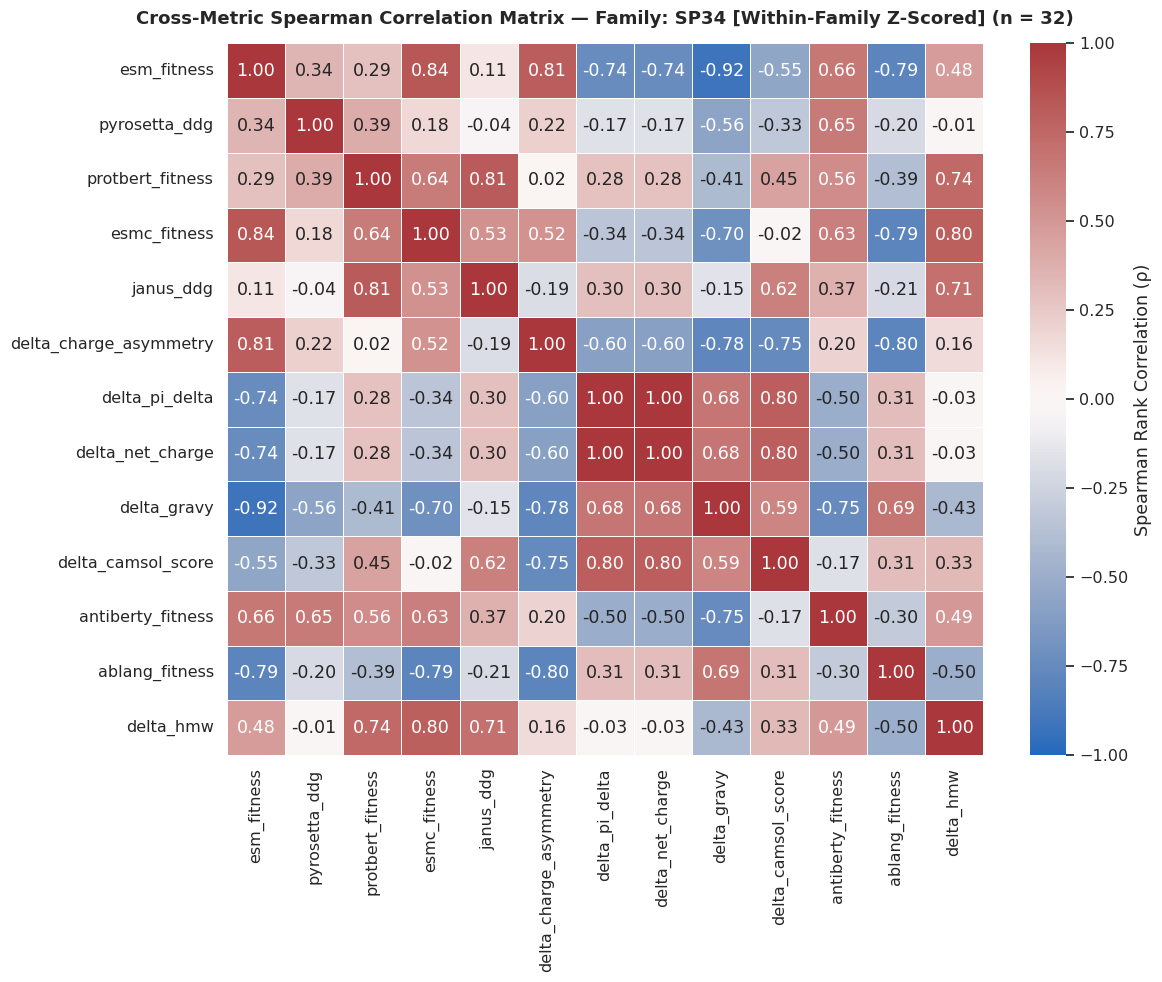

 -> Saved: metrics_cross_correlation_heatmap_zscore_SP34.png


In [45]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.preprocessing import StandardScaler

# Set clean plotting style
sns.set_theme(style="whitegrid", font_scale=1.05)

# Toggle: Z-score normalize delta_hmw within each family alongside the predictors
# True = Eliminates vertical cluster offset between families in Combined plots
ZSCORE_TARGET_HMW = True

# ==========================================
# 1. Load Data & Standardize Columns
# ==========================================
input_csv = "COMBINED_developability_metrics.csv"
df = pd.read_csv(input_csv)
df.columns = df.columns.str.strip()

reverse_rename_map = {
    'ID': 'id', 'Sequence ID': 'id', 'Mutations': 'mutations',
    'Global Composite Score': 'global_composite_score',
    'Stability ΔΔG (Janus)': 'janus_ddg',
    'Stability ΔΔG (PyRosetta)': 'pyrosetta_ddg',
    'Intrinsic Solubility (CamSol)': 'camsol_score',
    'Isoelectric Point (pI)': 'pI',
    'Hydrophobicity Index (GRAVY)': 'gravy',
    'Net Charge (pH 7.4)': 'net_charge',
    'VH-VL Charge Delta': 'charge_asymmetry',
    'Affinity Log10 Kd (BINDPRED)': 'bindpred_kd',
    'ΔLog-Likelihood (ESM-2 General)': 'esm_fitness',
    'ΔLog-Likelihood (ESM-C)': 'esmc_fitness',
    'ΔLog-Likelihood (AntiBERTy)': 'antiberty_fitness',
    'ΔLog-Likelihood (AbLang2 Paired)': 'ablang_fitness',
    'ΔLog-Likelihood (ProtBERT)': 'protbert_fitness',
    'VH Sequence': 'VH', 'VL Sequence': 'VL'
}
df = df.rename(columns=reverse_rename_map)
df['pi_delta'] = (df['pI'] - 7.4).abs()

def count_muts(m):
    m_str = str(m).strip()
    if m_str in ['WT', 'nan', '']:
        return 0
    return len(m_str.split(','))

df['num_mutations'] = df['mutations'].apply(count_muts)

# ==========================================
# 2. Compute Within-Family Deltas & Z-Scores Before Pooling
# ==========================================
intrinsic_cols = [
    'camsol_score', 'gravy', 'charge_asymmetry', 
    'bindpred_kd', 'pi_delta', 'net_charge'
]
already_relative_cols = [
    'janus_ddg', 'pyrosetta_ddg', 'esm_fitness', 'esmc_fitness', 
    'antiberty_fitness', 'ablang_fitness', 'protbert_fitness', 'num_mutations'
]
all_feature_cols = [f'delta_{c}' for c in intrinsic_cols] + already_relative_cols

normalized_family_dfs = []

for fam, group in df.groupby('family'):
    group = group.copy()
    wt_matches = group[group['mutations'].astype(str).str.strip() == 'WT']
    if wt_matches.empty:
        print(f" -> WARNING: No WT row found for family '{fam}'. Skipping family.")
        continue
    wt_row = wt_matches.iloc[0]
    
    # Step 2A: Compute raw deltas relative to family WT
    group['raw_delta_hmw'] = group['hmw'] - wt_row['hmw']
    group['delta_hmw'] = group['raw_delta_hmw']
    
    for col in intrinsic_cols:
        if col in group.columns:
            group[f'delta_{col}'] = group[col] - wt_row[col]
            
    # Step 2B: Isolate mutants BEFORE Z-scoring so the WT row doesn't skew family mean/std
    mut_group = group[group['mutations'].astype(str).str.strip() != 'WT'].dropna(subset=['delta_hmw']).copy()
    if len(mut_group) < 3:
        continue

    # Step 2C: Within-Family Z-Score Normalization (mean = 0, std = 1 per family)
    scaler = StandardScaler()
    cols_to_scale = [c for c in all_feature_cols if c in mut_group.columns]
    if ZSCORE_TARGET_HMW:
        cols_to_scale.append('delta_hmw')

    for col in cols_to_scale:
        valid_idx = mut_group[col].dropna().index
        if len(valid_idx) > 1 and mut_group.loc[valid_idx, col].nunique() > 1:
            mut_group.loc[valid_idx, col] = scaler.fit_transform(
                mut_group.loc[valid_idx, [col]]
            ).flatten()
        else:
            # Zero-variance column within this family
            mut_group.loc[valid_idx, col] = 0.0

    normalized_family_dfs.append(mut_group)

# Pool the within-family Z-scored dataframes
mutants = pd.concat(normalized_family_dfs, ignore_index=True)

families_in_csv = sorted(mutants['family'].astype(str).unique())
combined_file_tag = "_".join([re.sub(r'\W+', '', f) for f in families_in_csv])
combined_title_label = f"Combined Families ({', '.join(families_in_csv)}) [Within-Family Z-Scored]"

# ==========================================
# 3. Metric Definitions
# ==========================================
expected_good_direction = {
    'delta_camsol_score':     (+1, 'Higher Solubility (ΔCamSol Z)'),
    'janus_ddg':              (+1, 'Higher Stability (Janus ΔΔG Z)'),
    'delta_pi_delta':         (+1, 'Further from pH 7.4 (Δ|pI-7.4| Z)'),
    'delta_charge_asymmetry': (-1, 'Lower VH-VL Dipole (-ΔCharge Asym Z)'),
    'delta_net_charge':       (+1, 'Higher Net Charge (ΔNet Charge Z)'),
    'delta_gravy':            (-1, 'Lower Hydrophobicity (-ΔGRAVY Z)'),
    'delta_bindpred_kd':      (-1, 'Tighter VH-VL Affinity (-ΔBINDPRED Z)'),
    'pyrosetta_ddg':          (-1, 'Lower PyRosetta Energy (-PyRosetta ΔΔG Z)'),
    'esm_fitness':            (+1, 'Higher ESM-2 Fitness (Z)'),
    'esmc_fitness':           (+1, 'Higher ESM-C Fitness (Z)'),
    'antiberty_fitness':      (+1, 'Higher AntiBERTy Fitness (Z)'),
    'ablang_fitness':         (-1, 'Higher AbLang2 Fitness (Z)'),
    'protbert_fitness':       (+1, 'Higher ProtBERT Fitness (Z)'),
    'num_mutations':          (+1, 'Number of Mutations (Confounder Check Z)')
}

all_scatter_metrics = [
    ('esm_fitness',            'ESM-2 Fitness (Within-Family Z) [↑ Better]'),
    ('pyrosetta_ddg',          'PyRosetta ΔΔG (Within-Family Z) [↓ Better]'),
    ('protbert_fitness',       'ProtBERT Fitness (Within-Family Z) [↑ Better]'),
    ('esmc_fitness',           'ESM-C Fitness (Within-Family Z) [↑ Better]'),
    ('janus_ddg',              'JanusDDG Stability (Within-Family Z) [↑ Better]'),
    ('delta_charge_asymmetry', 'ΔVH-VL Charge Dipole (Within-Family Z) [↓ Better]'),
    ('delta_pi_delta',         'Δ|pI - 7.4| Distance (Within-Family Z) [↑ Better]'),
    ('delta_net_charge',       'ΔNet Charge pH 7.4 (Within-Family Z) [↑ Better]'),
    ('delta_gravy',            'ΔGRAVY Hydrophobicity (Within-Family Z) [↓ Better]'),
    ('delta_camsol_score',     'ΔCamSol Solubility (Within-Family Z) [↑ Better]'),
    ('antiberty_fitness',      'AntiBERTy Fitness (Within-Family Z) [↑ Better]'),
    ('ablang_fitness',         'AbLang2 Paired Score (Within-Family Z) [↓ Better]')
]

hmw_axis_label = "Wet-Lab Δ%HMW (Within-Family Z-Score) [↓ Better]" if ZSCORE_TARGET_HMW else "Wet-Lab Δ%HMW (%) [↓ Better]"

# ==========================================
# 4. Modular Analysis & Plotting Function
# ==========================================
def run_developability_analysis(sub_df, title_label, file_tag):
    sub_df = sub_df.copy()
    n_samples = len(sub_df)
    print(f"\n{'='*80}")
    print(f" RUNNING ANALYSIS: {title_label} (n = {n_samples} variants)")
    print(f"{'='*80}")

    # --- A. Spearman Correlation Table ---
    corr_rows = []
    for col, (sign_dir, label) in expected_good_direction.items():
        if col not in sub_df.columns:
            continue
        valid = sub_df[['delta_hmw', col]].dropna()
        if len(valid) > 3 and valid[col].nunique() > 1:
            raw_rho, pval = spearmanr(valid[col], valid['delta_hmw'])
            anti_agg_rho = -1.0 * sign_dir * raw_rho
            stars = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else "ns"))
            corr_rows.append({
                'Metric': label,
                'Raw_col': col,
                'Raw_Rho_vs_HMW': raw_rho,
                'Anti_Aggregation_Signal': anti_agg_rho,
                'p_value': pval,
                'Sig': stars
            })

    corr_df = pd.DataFrame(corr_rows).sort_values(by='Anti_Aggregation_Signal', ascending=False)
    print("\n--- 1. BIOPHYSICAL SIGNAL RANKING ---")
    if not corr_df.empty:
        print(corr_df[['Metric', 'Anti_Aggregation_Signal', 'Raw_Rho_vs_HMW', 'p_value', 'Sig']].to_string(index=False))

    # --- B. Biophysical Anti-Aggregation Composite Score & Tiers ---
    # Columns are already Within-Family Z-scored; we orient them so Positive = Anti-Aggregation
    pillars = pd.DataFrame(0.0, index=sub_df.index, columns=[
        'pyrosetta', 'janus', 'esm2', 'esmc', 'low_dipole', 'repulsion', 'gravy', 'camsol'
    ])

    pillar_specs = [
        ('pyrosetta',  'pyrosetta_ddg',          -1.0),
        ('janus',      'janus_ddg',              +1.0),
        ('esm2',       'esm_fitness',            +1.0),
        ('esmc',       'esmc_fitness',           +1.0),
        ('low_dipole', 'delta_charge_asymmetry', -1.0),
        ('repulsion',  'delta_pi_delta',         +1.0),
        ('gravy',      'delta_gravy',            -1.0),
        ('camsol',     'delta_camsol_score',     +1.0)
    ]

    for p_name, col_name, direction in pillar_specs:
        if col_name in sub_df.columns:
            pillars[p_name] = direction * sub_df[col_name].fillna(0.0)

    sub_df['biophysical_anti_agg_score'] = (
        0.20 * pillars['pyrosetta'] +
        0.20 * pillars['janus'] +
        0.15 * pillars['esm2'] +
        0.15 * pillars['esmc'] +
        0.10 * pillars['low_dipole'] +
        0.10 * pillars['repulsion'] +
        0.05 * pillars['gravy'] +
        0.05 * pillars['camsol']
    )

    tier_labels = ['Bottom 25%\n(High Risk)', 'Middle 50%\n(Moderate)', 'Top 25%\n(Best Biophysical Leads)']
    sub_df['Tier'] = pd.qcut(
        sub_df['biophysical_anti_agg_score'].rank(method='first'),
        q=[0, 0.25, 0.75, 1.0],
        labels=tier_labels
    )

    print("\n--- 2. WET-LAB Δ%HMW BY PREDICTED BIOPHYSICAL TIER (Z-Score & Raw %) ---")
    tier_summary = sub_df.groupby('Tier', observed=False).agg(
        count=('delta_hmw', 'count'),
        z_hmw_median=('delta_hmw', 'median'),
        z_hmw_mean=('delta_hmw', 'mean'),
        raw_hmw_median=('raw_delta_hmw', 'median'),
        raw_hmw_mean=('raw_delta_hmw', 'mean')
    )
    print(tier_summary)

    # =========================================================
    # FIGURE 1: 2-Panel Diagnostic Figure (Signal + Tiers)
    # =========================================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
    plt.subplots_adjust(wspace=0.35)

    # Panel A: Horizontal Bar Chart of Anti-Aggregation Signal
    ax1 = axes[0]
    plot_corr = corr_df[corr_df['Raw_col'] != 'num_mutations'].sort_values('Anti_Aggregation_Signal', ascending=True)
    if not plot_corr.empty:
        colors = ['#2ca02c' if val > 0 else '#d62728' for val in plot_corr['Anti_Aggregation_Signal']]
        bars = ax1.barh(plot_corr['Metric'], plot_corr['Anti_Aggregation_Signal'], color=colors, alpha=0.85, edgecolor='black')
        ax1.axvline(0, color='black', linewidth=1)
        ax1.set_title("A. Predictive Signal for Reducing %HMW (Spearman)", fontweight='bold')
        ax1.set_xlabel("← Inverse Signal (PLM Trade-off) | Correct Anti-Aggregation Signal →")
        
        for bar, sig in zip(bars, plot_corr['Sig']):
            width = bar.get_width()
            offset = 0.02 if width >= 0 else -0.06
            ax1.text(width + offset, bar.get_y() + bar.get_height()/2, sig, va='center', fontweight='bold')
        
        min_x = min(-0.5, plot_corr['Anti_Aggregation_Signal'].min() - 0.15)
        max_x = max(0.6, plot_corr['Anti_Aggregation_Signal'].max() + 0.15)
        ax1.set_xlim(min_x, max_x)

    # Panel B: Boxplot of Wet-Lab Δ%HMW across Predicted Biophysical Tiers
    ax2 = axes[1]
    sns.boxplot(
        data=sub_df, x='Tier', y='delta_hmw', ax=ax2,
        palette=['#ff9896', '#aec7e8', '#98df8a'], showfliers=False, width=0.5
    )
    sns.stripplot(
        data=sub_df, x='Tier', y='delta_hmw', ax=ax2,
        hue='family', dodge=False, alpha=0.6, jitter=0.18, size=5.5
    )
    ax2.axhline(0, color='gray', linestyle=':', linewidth=1.2)
    
    top_hmw = sub_df[sub_df['Tier'] == 'Top 25%\n(Best Biophysical Leads)']['delta_hmw']
    bot_hmw = sub_df[sub_df['Tier'] == 'Bottom 25%\n(High Risk)']['delta_hmw']
    mw_pval = mannwhitneyu(top_hmw, bot_hmw)[1] if (len(top_hmw) > 0 and len(bot_hmw) > 0) else np.nan

    ax2.set_title(f"B. Wet-Lab Aggregation by Biophysical Tier (p = {mw_pval:.2e})", fontweight='bold')
    ax2.set_xlabel("Within-Family Biophysical Score Tier (Stability + Electrostatics + PLMs)")
    ax2.set_ylabel(hmw_axis_label)

    fig.suptitle(f"Developability Benchmark Diagnostics: {title_label} (n = {n_samples})", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    diag_filename = f"hmw_benchmark_diagnostics_zscore_{file_tag}.png"
    plt.savefig(diag_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {diag_filename}")

    # =========================================================
    # FIGURE 2: 3x4 Grid of All 12 Metrics vs. Wet-Lab Δ%HMW
    # =========================================================
    fig, axes = plt.subplots(3, 4, figsize=(22, 15))
    plt.subplots_adjust(hspace=0.40, wspace=0.28)
    axes_flat = axes.flatten()

    for idx, (col, label) in enumerate(all_scatter_metrics):
        ax = axes_flat[idx]
        if col not in sub_df.columns:
            ax.set_visible(False)
            continue
            
        valid = sub_df[[col, 'delta_hmw', 'family']].dropna()
        
        if len(valid) <= 3 or valid[col].nunique() <= 1:
            ax.text(0.5, 0.5, f"{col}\n(Constant / No Variance)", ha='center', va='center', fontsize=12)
            ax.set_title(f"{idx+1}. {col} (Constant)", fontweight='bold', fontsize=11)
            continue

        rho, pval = spearmanr(valid[col], valid['delta_hmw'])
        stars = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else "ns"))
        
        # Plot regression trendline across all points
        sns.regplot(
            data=valid, x=col, y='delta_hmw', ax=ax,
            scatter=False,
            line_kws={'color': 'crimson', 'linestyle': '--', 'linewidth': 2}
        )
        # Color points by family to visually verify cluster alignment
        sns.scatterplot(
            data=valid, x=col, y='delta_hmw', hue='family', ax=ax,
            alpha=0.7, edgecolor='k', s=45, legend=(idx == 0)
        )
        
        ax.axvline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.axhline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.set_title(f"{idx+1}. {col}\n(Spearman ρ = {rho:+.2f} {stars}, p = {pval:.1e})", fontweight='bold', fontsize=11)
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel(hmw_axis_label if idx % 4 == 0 else "", fontsize=10)

    fig.suptitle(
        f"Comprehensive Benchmark: All 12 In Silico Metrics vs. Wet-Lab Δ%HMW — {title_label} (n = {n_samples})",
        fontsize=16, fontweight='bold', y=1.01
    )
    plt.tight_layout()
    grid_filename = f"all_metrics_scatter_grid_zscore_{file_tag}.png"
    plt.savefig(grid_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {grid_filename}")

    # =========================================================
    # FIGURE 3: Cross-Metric Spearman Correlation Heatmap
    # =========================================================
    heatmap_cols = [c for c, _ in all_scatter_metrics if c in sub_df.columns and sub_df[c].dropna().nunique() > 1] + ['delta_hmw']
    corr_matrix = sub_df[heatmap_cols].corr(method='spearman')

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        corr_matrix, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
        linewidths=0.5, cbar_kws={"label": "Spearman Rank Correlation (ρ)"}
    )
    plt.title(
        f"Cross-Metric Spearman Correlation Matrix — {title_label} (n = {n_samples})",
        fontweight='bold', fontsize=13, pad=14
    )
    plt.tight_layout()
    heatmap_filename = f"metrics_cross_correlation_heatmap_zscore_{file_tag}.png"
    plt.savefig(heatmap_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {heatmap_filename}")


# ==========================================
# 5. Execute for Combined & Individual Families
# ==========================================
# 1. Run Combined Analysis across all families
run_developability_analysis(
    sub_df=mutants,
    title_label=combined_title_label,
    file_tag=f"combined_{combined_file_tag}"
)

# 2. Run Individual Family Analyses
for fam in families_in_csv:
    fam_subset = mutants[mutants['family'].astype(str) == fam]
    clean_fam_tag = re.sub(r'\W+', '', fam)
    run_developability_analysis(
        sub_df=fam_subset,
        title_label=f"Family: {fam} [Within-Family Z-Scored]",
        file_tag=clean_fam_tag
    )

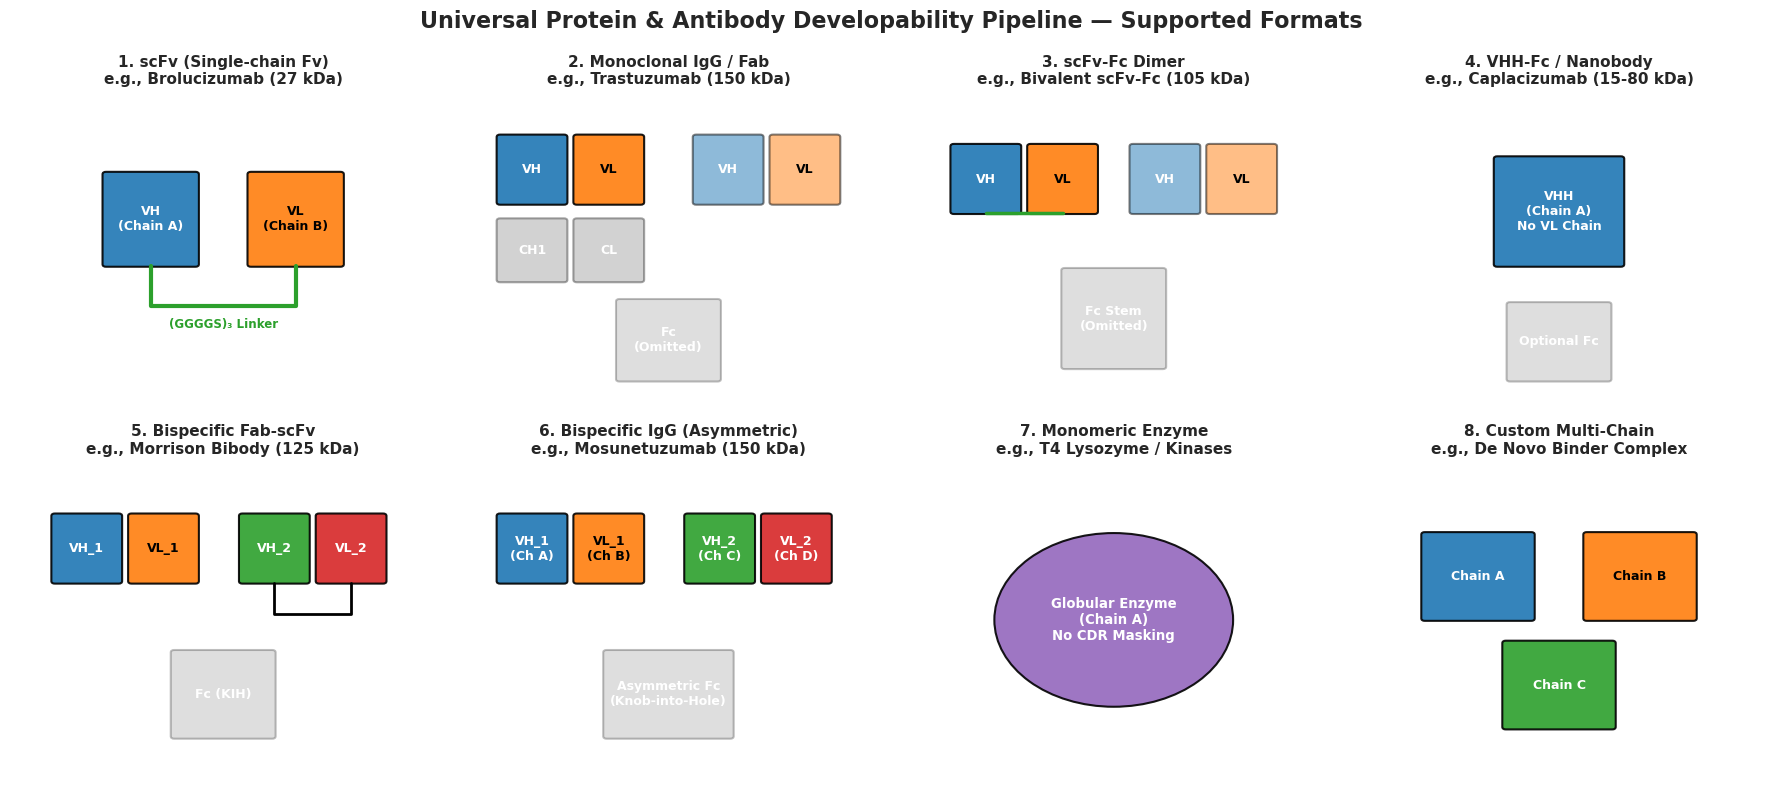

In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Universal Protein & Antibody Developability Pipeline — Supported Formats", fontsize=16, fontweight='bold', y=0.98)

def draw_domain(ax, x, y, w, h, label, color, ec='black', alpha=0.9):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", facecolor=color, edgecolor=ec, linewidth=1.5, alpha=alpha)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontweight='bold', fontsize=9, color='white' if color in ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#7f7f7f'] else 'black')

formats = [
    ("1. scFv (Single-chain Fv)\ne.g., Brolucizumab (27 kDa)", "scfv"),
    ("2. Monoclonal IgG / Fab\ne.g., Trastuzumab (150 kDa)", "igg"),
    ("3. scFv-Fc Dimer\ne.g., Bivalent scFv-Fc (105 kDa)", "scfv_fc"),
    ("4. VHH-Fc / Nanobody\ne.g., Caplacizumab (15-80 kDa)", "vhh"),
    ("5. Bispecific Fab-scFv\ne.g., Morrison Bibody (125 kDa)", "fab_scfv"),
    ("6. Bispecific IgG (Asymmetric)\ne.g., Mosunetuzumab (150 kDa)", "bs_igg"),
    ("7. Monomeric Enzyme\ne.g., T4 Lysozyme / Kinases", "enzyme"),
    ("8. Custom Multi-Chain\ne.g., De Novo Binder Complex", "custom")
]

for ax, (title, ftype) in zip(axes.flatten(), formats):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    
    if ftype == "scfv":
        draw_domain(ax, 2.2, 4.5, 2.2, 3.0, "VH\n(Chain A)", "#1f77b4")
        draw_domain(ax, 5.6, 4.5, 2.2, 3.0, "VL\n(Chain B)", "#ff7f0e")
        ax.plot([3.3, 3.3, 6.7, 6.7], [4.5, 3.2, 3.2, 4.5], color="#2ca02c", lw=3, label="Linker")
        ax.text(5.0, 2.5, "(GGGGS)₃ Linker", ha='center', fontsize=8.5, fontweight='bold', color="#2ca02c")
    elif ftype == "igg":
        # Left Fab + Right Fab + Fc (ghosted constant domains)
        draw_domain(ax, 1.0, 6.5, 1.6, 2.2, "VH", "#1f77b4")
        draw_domain(ax, 2.8, 6.5, 1.6, 2.2, "VL", "#ff7f0e")
        draw_domain(ax, 1.0, 4.0, 1.6, 2.0, "CH1", "#7f7f7f", alpha=0.35)
        draw_domain(ax, 2.8, 4.0, 1.6, 2.0, "CL", "#7f7f7f", alpha=0.35)
        draw_domain(ax, 5.6, 6.5, 1.6, 2.2, "VH", "#1f77b4", alpha=0.5)
        draw_domain(ax, 7.4, 6.5, 1.6, 2.2, "VL", "#ff7f0e", alpha=0.5)
        draw_domain(ax, 3.8, 0.8, 2.4, 2.6, "Fc\n(Omitted)", "#7f7f7f", alpha=0.25)
    elif ftype == "scfv_fc":
        draw_domain(ax, 1.2, 6.2, 1.6, 2.2, "VH", "#1f77b4")
        draw_domain(ax, 3.0, 6.2, 1.6, 2.2, "VL", "#ff7f0e")
        ax.plot([2.0, 3.8], [6.2, 6.2], color="#2ca02c", lw=2.5)
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH", "#1f77b4", alpha=0.5)
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL", "#ff7f0e", alpha=0.5)
        draw_domain(ax, 3.8, 1.2, 2.4, 3.2, "Fc Stem\n(Omitted)", "#7f7f7f", alpha=0.25)
    elif ftype == "vhh":
        draw_domain(ax, 3.5, 4.5, 3.0, 3.5, "VHH\n(Chain A)\nNo VL Chain", "#1f77b4")
        draw_domain(ax, 3.8, 0.8, 2.4, 2.5, "Optional Fc", "#7f7f7f", alpha=0.25)
    elif ftype == "fab_scfv":
        draw_domain(ax, 1.0, 6.2, 1.6, 2.2, "VH_1", "#1f77b4")
        draw_domain(ax, 2.8, 6.2, 1.6, 2.2, "VL_1", "#ff7f0e")
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH_2", "#2ca02c")
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL_2", "#d62728")
        ax.plot([6.2, 6.2, 8.0, 8.0], [6.2, 5.2, 5.2, 6.2], color="black", lw=2)
        draw_domain(ax, 3.8, 1.2, 2.4, 2.8, "Fc (KIH)", "#7f7f7f", alpha=0.25)
    elif ftype == "bs_igg":
        draw_domain(ax, 1.0, 6.2, 1.6, 2.2, "VH_1\n(Ch A)", "#1f77b4")
        draw_domain(ax, 2.8, 6.2, 1.6, 2.2, "VL_1\n(Ch B)", "#ff7f0e")
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH_2\n(Ch C)", "#2ca02c")
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL_2\n(Ch D)", "#d62728")
        draw_domain(ax, 3.5, 1.2, 3.0, 2.8, "Asymmetric Fc\n(Knob-into-Hole)", "#7f7f7f", alpha=0.25)
    elif ftype == "enzyme":
        circ = patches.Circle((5.0, 5.0), 2.8, facecolor="#9467bd", edgecolor="black", lw=1.5, alpha=0.9)
        ax.add_patch(circ)
        ax.text(5.0, 5.0, "Globular Enzyme\n(Chain A)\nNo CDR Masking", ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
    elif ftype == "custom":
        draw_domain(ax, 1.8, 5.0, 2.6, 2.8, "Chain A", "#1f77b4")
        draw_domain(ax, 5.6, 5.0, 2.6, 2.8, "Chain B", "#ff7f0e")
        draw_domain(ax, 3.7, 1.5, 2.6, 2.8, "Chain C", "#2ca02c")

plt.tight_layout()
plt.savefig("pipeline_protein_formats_overview.png", dpi=300)
plt.show()